<div style="background-color: black; color: white; padding: 10px;text-align: center;">
  <strong>Date Published:</strong> Nov 14, 2026 <strong>Author:</strong> Adnan Alaref
</div>

# **Section 0 — Dataset Overview.**


## 1. Dataset Overview

### 1.1 Introduction

The **Jabarti LLM Dataset** is a bilingual Arabic-English dataset designed to support the development and training of Large Language Models (LLMs) From Scratch.

It combines curated Egyptian historical content with **broader Wikipedia-based text**, providing **resources** for both language model **pretraining** and **supervised fine-tuning**.

The dataset is organized into two main configurations:

- **Pretraining:** A large-scale text corpus designed for language __model pretraining__.
- **Fine-tuning:** A collection of __question-answer pairs__ designed for __supervised fine-tuning (SFT)__.

In this notebook, we explore all available configurations and their associated splits to understand the dataset's __composition, structure, and characteristics__.

### 1.2 Dataset Metadata

| Property | Description |
|:--|:--|
| Dataset Name | Jabarti LLM Dataset |
| Provider | Bakrianoo |
| Languages | Arabic and English |
| Configurations | Pretrain and Finetune |
| Data Format | Parquet |
| Supported Tasks | Language Modeling and Question Answering |
| License | CC-BY-SA-4.0 |
| Platform | Hugging Face |

**Dataset Source:** [Jabarti LLM Dataset](https://huggingface.co/datasets/bakrianoo/jabarti-llm-dataset)

### 1.3 Dataset Structure

The dataset provides two main configurations, each serving a different purpose in the development of LLMs.

#### A. Pretraining Configuration

The pretraining configuration contains large-scale textual data intended for learning language patterns and representations.

| Split | Number of Records |
|:--|--:|
| `train` | 7,053,893 |
| `eval` | 114,259 |
| `phase1_train` | 175,476 |
| `phase1_eval` | 2,000 |
| `phase2_train` | 94,486 |
| `phase2_eval` | 2,001 |

#### B. Fine-tuning Configuration

The fine-tuning configuration contains question-answer pairs intended for supervised learning.

| Split | Number of Records |
|:--|--:|
| `train` | 57,488 |
| `eval` | 6,379 |

**Note:** The phase-specific splits represent additional dataset partitions. Their overlap with the main training and evaluation splits needs to be verified before calculating the total number of unique records.

### 1.4 Dataset Components

The two configurations provide different types of information:

| Configuration | Main Content | Primary Purpose |
|:--|:--|:--|
| Pretrain | Textual content | Language model pretraining |
| Finetune | Questions and answers | Supervised fine-tuning |

This distinction is important because each configuration requires different exploration techniques and evaluation criteria.

### 1.5 Initial Observations

Based on the dataset's organization, several important observations can be identified:

- The dataset supports both `Arabic` and `English` language modeling.
- It provides separate configurations for `pretraining` and `supervised fine-tuning`.
- The pretraining configuration contains substantially __more records than the fine-tuning__ configuration.
- The availability of multiple splits allows us to __investigate__ different stages of data preparation.
- The two configurations require different __approaches to statistical and linguistic analysis__.

These observations provide the foundation for the upcoming exploration sections, where we will investigate language distribution, text characteristics, and data quality in greater detail.


# **Section 1 — Import Libraries.**

In [1]:
!pip install datasets pandas >/dev/null 2>&1

In [2]:
from datasets import load_dataset
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
import seaborn as sns
import pandas as pd

import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=FutureWarning)

## **Section 1.1: Dataset Configurations.**

In [3]:
# Read dataset as batches
BATCH_SIZE = 10_000

# Rough token estimate for bilingual AR/EN.
CHARS_PER_TOKEN = 3.5

# Candidate model context lengths
CONTEXT_LENGTHS = [512, 1024, 2048]

# Subsets and splits
configs = {
  "pretrain": [
    "train",
    "eval",
    "phase1_train",
    "phase1_eval",
    "phase2_train",
    "phase2_eval"
  ],
  "finetune": ["train", "eval"]
}

# ── Dataset path  ──
REPO = "bakrianoo/jabarti-llm-dataset"

# **Section 2 — Language Distribution**

In [4]:
language_stats = []

# ── Extract language distribution
for config, splits in configs.items():

  for split in splits:

    dataset = load_dataset(
      REPO,
      config,
      split = split,
      streaming=True
    )

    language_counts = Counter()
    total_records = 0

    # ── Process dataset in batches
    batch = []

    for sample in tqdm(dataset, desc=f"{config}/{split}"):
      batch.append(sample["language"])

      if len(batch) == BATCH_SIZE:
        batch_counts = pd.Series(batch).value_counts()

        language_counts.update(batch_counts.to_dict())
        total_records += len(batch)

        batch.clear()

    # ── Process remaining records
    if batch:
      batch_counts = pd.Series(batch).value_counts()

      language_counts.update(batch_counts.to_dict())
      total_records += len(batch)

    for language, count in language_counts.items():
      language_stats.append({
        "Configuration": config,
        "Split": split,
        "Language": language,
        "Count": count,
        "Percentage": count / total_records * 100
      })

# ── Create results DataFrame
language_df = pd.DataFrame(language_stats)

display(
  language_df.round({"Percentage": 2})
)

README.md:   0%|          | 0.00/7.01k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

pretrain/train: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

... (14 outputs left out)

finetune/train: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

finetune/eval: 0it [00:00, ?it/s]

,Configuration,Split,Language,Count,Percentage
0,pretrain,train,en,3735826,52.96
1,pretrain,train,ar,3318067,47.04
2,pretrain,eval,en,59932,52.45
3,pretrain,eval,ar,54327,47.55
4,pretrain,phase1_train,en,125766,71.67
5,pretrain,phase1_train,ar,49710,28.33
6,pretrain,phase1_eval,en,1426,71.30
7,pretrain,phase1_eval,ar,574,28.70
8,pretrain,phase2_train,ar,52252,55.30
9,pretrain,phase2_train,en,42234,44.70


In [5]:
language_df.dtypes

Configuration     object
Split             object
Language          object
Count              int64
Percentage       float64
dtype: object

In [6]:
language_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Configuration  16 non-null     object 
 1   Split          16 non-null     object 
 2   Language       16 non-null     object 
 3   Count          16 non-null     int64  
 4   Percentage     16 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 772.0+ bytes


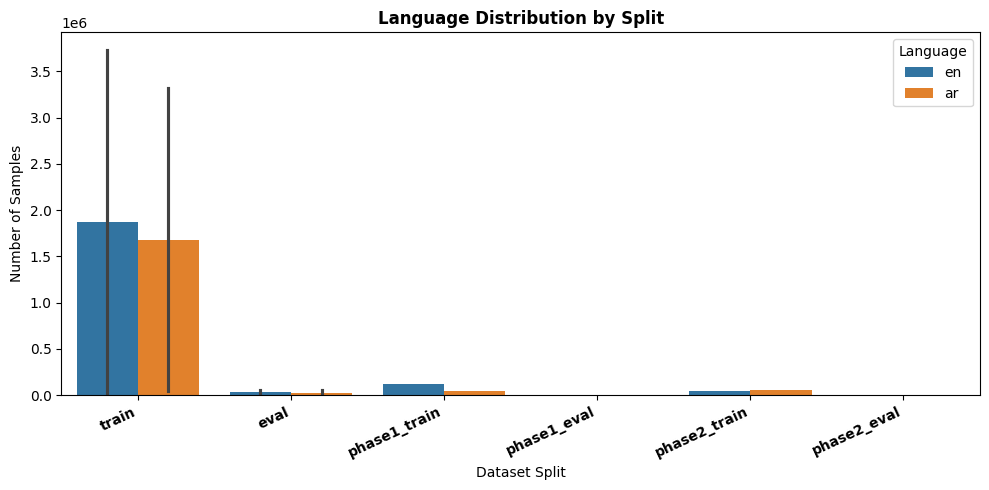

In [7]:
plt.figure(figsize=(10, 5), dpi=100)

sns.barplot(
  data = language_df,
  x = "Split",
  y = "Count",
  hue= "Language",
)

plt.title("Language Distribution by Split", loc="center", fontsize = 12, fontweight="bold")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Samples")
plt.xticks(rotation=25, ha="right", fontweight="bold")
plt.legend(title="Language", loc="best")

plt.tight_layout()
plt.show()

DataFrame Before:


Language,ar,en
Split,,
eval,59303,61335
phase1_eval,574,1426
phase1_train,49710,125766
phase2_eval,1072,929
phase2_train,52252,42234
train,3363014,3748367



DataFrame After:


Language,ar,en
Split,,
eval,49.1578,50.8422
phase1_eval,28.7000,71.3000
phase1_train,28.3287,71.6713
phase2_eval,53.5732,46.4268
phase2_train,55.3013,44.6987
train,47.2906,52.7094


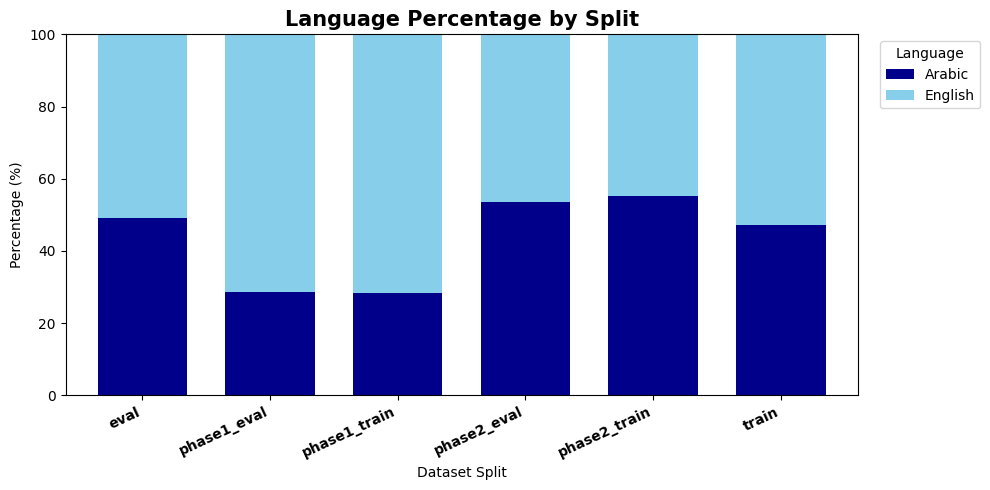

In [8]:
# Aggregate sample counts
percentage_df = language_df.pivot_table(
    index="Split",
    columns="Language",
    values="Count",
    aggfunc="sum",
    fill_value=0
)
print("DataFrame Before:")
display(
  percentage_df.style.set_properties(**{'background-color':'#2a9d8f','color':'white','border':'2.5px solid black'})
)

# Calculate percentages
percentage_df = percentage_df.div(
    percentage_df.sum(axis=1),
    axis=0
) * 100
print(f"\nDataFrame After:")
display(
  percentage_df.round(4).style.format("{:.4f}").set_properties(**{'background-color':'#2a9d8f','color':'white','border':'2.5px solid black'})
)


# Set language order
percentage_df = percentage_df[["ar", "en"]]

# Plot
ax = percentage_df.plot(
    kind="bar",
    stacked=True,
    width=0.7,
    figsize=(10, 5),
    color=["darkblue", "skyblue"]
)

ax.set_title("Language Percentage by Split", fontsize=15, fontweight="bold")
ax.set_xlabel("Dataset Split", loc="center", fontsize = 10)
ax.set_ylabel("Percentage (%)", loc="center", fontsize = 10)
ax.set_ylim(0, 100)
ax.legend(
  title="Language", labels=["Arabic", "English"],
  bbox_to_anchor=(1.02, 1), loc="upper left"
)

plt.xticks(rotation=25, ha="right", fontweight="bold")
plt.tight_layout()
plt.show()

**Key Findings**

- The main __pretraining dataset has a relatively balanced language distribution__, with approximately `53% English` and `47% Arabic`.
- Phase 1 is __English-dominant__, while Phase 2 has a __slight Arabic majority__.
- The __fine-tuning dataset is predominantly Arabic__, with approximately `78% Arabic` and `22% English`.
- `Training` and `evaluation` splits exhibit __similar language distributions within each configuration__.


# **Section 3 — Question Analysis.**

## **Section 3.1: Dataset Schema Inspection.**

In [9]:
for config in configs.keys():
  iter_dataset = load_dataset(
    REPO,
    config,
    split="train",
    streaming=True
  )

  record = next(iter(iter_dataset))
  print(f"\n{config.upper()} Columns:")
  print(record.keys())


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]


PRETRAIN Columns:
dict_keys(['article_id', 'title', 'url', 'language', 'category', 'source_type', 'egypt_relevance', 'content_quality', 'topic_domain', 'importance', 'is_person', 'is_stub_like', 'ortho_convention', 'pageviews_30d', 'chunk_strategy', 'chunk_index', 'chunk_total', 'pair_id', 'dataset_version', 'ds_source', 'text', 'section_index', 'section_total', 'ortho_stripped', 'page_id', 'record_id', 'sample_weight'])


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]


FINETUNE Columns:
dict_keys(['difficulty', 'type', 'qa_id', 'dataset_version', 'question', 'article_title', 'answer', 'source_article_id', 'language'])


## **Section 3.2: Question Sampling.**

### **Way1**

In [10]:
finetune_train_stream = load_dataset(
  REPO,
  "finetune",
  split = "train",
  streaming = True
)

# To see the first 3 questions from a streamed dataset:
for sample in finetune_train_stream.take(3):
   print(sample["question"])

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

من هي شپنوپت الأولى؟
أين دُفنت شپنوپت الأولى؟
كيف أسهمت شپنوپت الأولى في تحويل منصب زوجة آمون الإلهية إلى سلطة سياسية؟


### **Way2**

In [11]:
from itertools import islice
finetune_train_stream2 = load_dataset(
  REPO,
  "finetune",
  split = "train",
  streaming = True
)

# Display the questions from record 2 to 7
for sample in islice(finetune_train_stream2, 2, 7):
    print(sample["question"])

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

كيف أسهمت شپنوپت الأولى في تحويل منصب زوجة آمون الإلهية إلى سلطة سياسية؟
من كان والد فريد سيمائيكا؟
متى وأين توفي فريد سيمائيكا؟
كيف أظهرت مسيرة فريد سيمائيكا تنوعًا في مواهبه؟
من هو حسن باشا الاسكندراني؟


## **Section 3.3: Investigate [question, type, difficulty, language] Columns.**

In [12]:
selected_columns = ["question", "type", "difficulty", "language"]
select_train_columns = load_dataset(
  REPO,
  "finetune",
  split = "train",
  streaming = True
)

data = []
# Select some columns from a streamed dataset:
for sample in select_train_columns.take(10):
  data.append({
    col: sample[col] for col in selected_columns
  })

pd.DataFrame(data)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

,question,type,difficulty,language
0,من هي شپنوپت الأولى؟,factual,easy,ar
1,أين دُفنت شپنوپت الأولى؟,temporal,easy,ar
2,كيف أسهمت شپنوپت الأولى في تحويل منصب زوجة آمو...,analytical,hard,ar
3,من كان والد فريد سيمائيكا؟,factual,easy,ar
4,متى وأين توفي فريد سيمائيكا؟,temporal,easy,ar
5,كيف أظهرت مسيرة فريد سيمائيكا تنوعًا في مواهبه؟,analytical,hard,ar
6,من هو حسن باشا الاسكندراني؟,factual,easy,ar
7,أين توفي حسن باشا الاسكندراني؟,temporal,easy,ar
8,كيف ساهمت حياة حسن باشا الاسكندراني في إبراز د...,analytical,hard,ar
9,ما الشهادة التي حصل عليها هاني عبد العزيز من ج...,factual,easy,ar


## **Section 3.4: Question Type Distribution.**

In [13]:
type__stats = []
for split in configs["finetune"]:
  dataset = load_dataset(
    REPO,
    "finetune",
    split = split,
    streaming= True,
  )

  batch = []
  type_counts = Counter()

  for record in dataset:
    batch.append(record["type"])

    if len(batch) == BATCH_SIZE:
      batch_counts = pd.Series(batch).value_counts()

      type_counts.update(batch_counts.to_dict())
      batch.clear()

  if batch:
    batch_counts = pd.Series(batch).value_counts()
    type_counts.update(batch_counts.to_dict())


  for type_name, count in type_counts.items():
    type__stats.append({
      "Configuration": "finetune",
      "Split": split,
      "Type": type_name,
      "Count": count
    })

type_df = pd.DataFrame(type__stats)

display(
  type_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

,Configuration,Split,Type,Count
0,finetune,train,temporal,18157
1,finetune,train,analytical,17761
2,finetune,train,factual,17752
3,finetune,train,synthesis,2615
4,finetune,train,unanswerable,1203
5,finetune,eval,temporal,2027
6,finetune,eval,analytical,1980
7,finetune,eval,factual,1965
8,finetune,eval,synthesis,295
9,finetune,eval,unanswerable,111


In [14]:
type_df.describe().style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})

,Count
count,11.00
mean,5806.09
std,7808.46
min,1.00
25%,749.00
50%,1980.00
75%,10183.50
max,18157.00


In [15]:
eval_dataset = load_dataset(
  REPO,
  "finetune",
  split = "eval",
  streaming= True,
)

for sample in eval_dataset:
  record = sample["type"]

  if record == "unknown":
    unknown_record = sample
    break

pd.DataFrame([unknown_record]).style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

,difficulty,type,qa_id,dataset_version,question,article_title,answer,source_article_id,language
0,medium,unknown,train_phase_2#10033_qa3,2.0.0,ما أبرز إنجاز حققه سعد الدين باشا الازم خلال حكمه لمصر؟,سعد الدين باشا الازم: حاكم عثماني متعدد الولايات,لا تتوفر هذه المعلومة,train_phase_2#10033,ar


In [16]:
type_table = type_df.pivot_table(
  index="Split",
  columns="Type",
  values = "Count",
  aggfunc="sum",
  fill_value=0
)

display(
  type_table.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Type,analytical,factual,synthesis,temporal,unanswerable,unknown
Split,,,,,,
eval,1980,1965,295,2027,111,1
train,17761,17752,2615,18157,1203,0


In [17]:
type_percentage = (type_table.div(type_table.sum(axis=1), axis=0) * 100)
display(
  type_percentage.style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Type,analytical,factual,synthesis,temporal,unanswerable,unknown
Split,,,,,,
eval,31.04,30.80,4.62,31.78,1.74,0.02
train,30.90,30.88,4.55,31.58,2.09,0.00


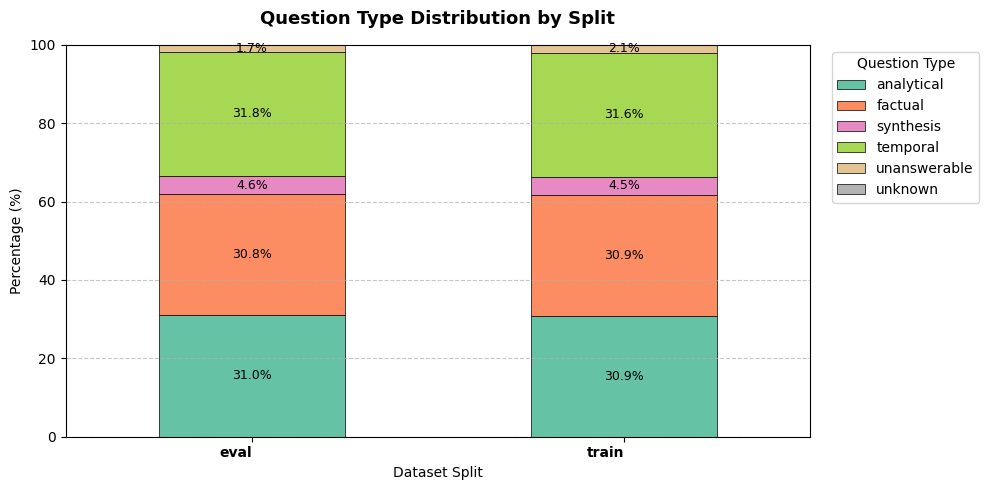

In [18]:
ax = type_percentage.plot(
  kind="bar",
  stacked=True,
  figsize=(10, 5),
  colormap="Set2",
  edgecolor="black",
  linewidth=0.5,
)

# Add percentage labels
for container in ax.containers:
  labels = [
    f"{bar.get_height():.1f}%" if bar.get_height() > 1 else ""
    for bar in container
  ]
  ax.bar_label(
    container,
    labels=labels,
    label_type="center",
    fontsize=9
  )

plt.title("Question Type Distribution by Split", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Dataset Split")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0, ha="right", fontweight="bold")
plt.ylim(0, 100)

plt.legend(title="Question Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Key Findings:**  

- **Dominant Question Types:** Temporal, analytical, and factual questions account for the largest proportion of the fine-tuning dataset.
- **Less Frequent Types:** Synthesis and unanswerable questions are considerably less represented than the three dominant types.
- **Consistent Distribution:** The distribution of question types is broadly similar across the training and evaluation splits.
- **Unknown Category:** One record in the evaluation split has an `unknown` question type, representing a small data inconsistency worth documenting.

Overall, the fine-tuning dataset contains a similar distribution of question types across both splits, with a clear concentration in temporal, analytical, and factual questions.

## **Section 3.5: Question Difficulty Distribution**

In [19]:
difficulty_stats = []
for split in configs["finetune"]:
  dataset = load_dataset(
    REPO,
    "finetune",
    split = split,
    streaming= True,
  )

  batch = []
  difficulty_counts = Counter()

  for record in dataset:
    batch.append(record["difficulty"])

    if len(batch) == BATCH_SIZE:
      batch_counts = pd.Series(batch).value_counts()

      difficulty_counts.update(batch_counts.to_dict())
      batch.clear()

  if batch:
    batch_counts = pd.Series(batch).value_counts()
    difficulty_counts.update(batch_counts.to_dict())


  for difficulty_name, count in difficulty_counts.items():
    difficulty_stats.append({
      "Configuration": "finetune",
      "Split": split,
      "Difficulty": difficulty_name,
      "Count": count
    })

difficulty_df = pd.DataFrame(difficulty_stats)

display(
  difficulty_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

,Configuration,Split,Difficulty,Count
0,finetune,train,easy,27500
1,finetune,train,hard,17126
2,finetune,train,medium,12862
3,finetune,eval,easy,3050
4,finetune,eval,hard,1897
5,finetune,eval,medium,1432


In [20]:
difficulty_df.describe().style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})

,Count
count,6.00
mean,10644.50
std,10489.05
min,1432.00
25%,2185.25
50%,7956.00
75%,16060.00
max,27500.00


In [21]:
difficulty_table = difficulty_df.pivot_table(
  index="Split",
  columns="Difficulty",
  values = "Count",
  aggfunc="sum",
  fill_value=0
)

display(
  difficulty_table.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Difficulty,easy,hard,medium
Split,,,
eval,3050,1897,1432
train,27500,17126,12862


In [22]:
difficulty_percentage = (
  difficulty_table.div(
    difficulty_table.sum(axis=1),
    axis=0
  ) * 100
)

display(
  difficulty_percentage.style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Difficulty,easy,hard,medium
Split,,,
eval,47.81,29.74,22.45
train,47.84,29.79,22.37


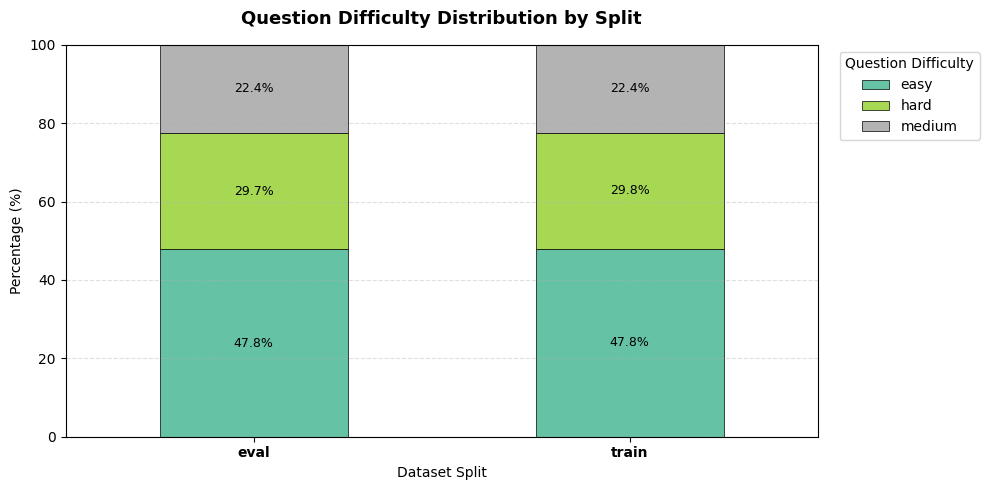

In [23]:
ax = difficulty_percentage.plot(
  kind="bar",
  stacked=True,
  figsize=(10, 5),
  colormap="Set2",
  edgecolor="black",
  linewidth=0.5,
)

# Add percentage labels
for container in ax.containers:
  labels = [
    f"{bar.get_height():.1f}%" if bar.get_height() > 1 else ""
    for bar in container
  ]
  ax.bar_label(
    container,
    labels=labels,
    label_type="center",
    fontsize=9
  )

plt.title("Question Difficulty Distribution by Split", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Dataset Split")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0, ha="center", fontweight="bold")
plt.ylim(0, 100)

plt.legend(title="Question Difficulty", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Key Findings:**

- **Dominant Difficulty Level:** Easy questions represent __the largest proportion__ of the fine-tuning dataset in both training and evaluation splits.
- **Hard Questions:** Hard questions account for __the second-largest proportion__ across both splits.
- **Least Frequent Level:** Medium questions are __the least represented difficulty level__.
- **Consistent Distribution:** The ranking and overall distribution of difficulty levels are broadly similar across the training and evaluation splits.

Overall, the fine-tuning dataset contains a higher proportion of `easy` questions, while `medium` and `hard` questions are less represented.

## **Section 3.6: Question Length Analysis.**

In [24]:
Word_count = []

for split in configs["finetune"]:
  dataset = load_dataset(
    REPO,
    "finetune",
    split = split,
    streaming=True
  )

  for record in dataset:
    question_words_count = len(record["question"].split())
    Word_count.append({
        "Split": split,
        "Count": question_words_count
    })

words_df = pd.DataFrame(Word_count)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

In [25]:
display(
  words_df.sample(10).style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

,Split,Count
32043,train,14
56061,train,11
52666,train,11
43688,train,5
59901,eval,11
39767,train,16
54110,train,15
17333,train,7
20325,train,10
50620,train,9


In [26]:
display(
  words_df.groupby("Split")["Count"].describe().style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

,count,mean,std,min,25%,50%,75%,max
Split,,,,,,,,
eval,6379.00,10.79,3.80,3.00,8.00,11.00,13.00,28.00
train,57488.00,10.86,3.85,3.00,8.00,11.00,13.00,43.00


**Key Findings:**

- **Similar Average Length:** The average question length is nearly identical across the training and evaluation splits (10.86 vs. 10.79 words).
- **Consistent Distribution:** Both splits share the same median (11 words), first quartile (8 words), and third quartile (13 words).
- **Similar Variability:** The standard deviation is comparable across both splits (3.85 vs. 3.80 words).
- **Maximum Length:** The longest question contains 43 words in the training split and 28 words in the evaluation split.

Overall, the training and evaluation splits exhibit highly similar question-length distributions.

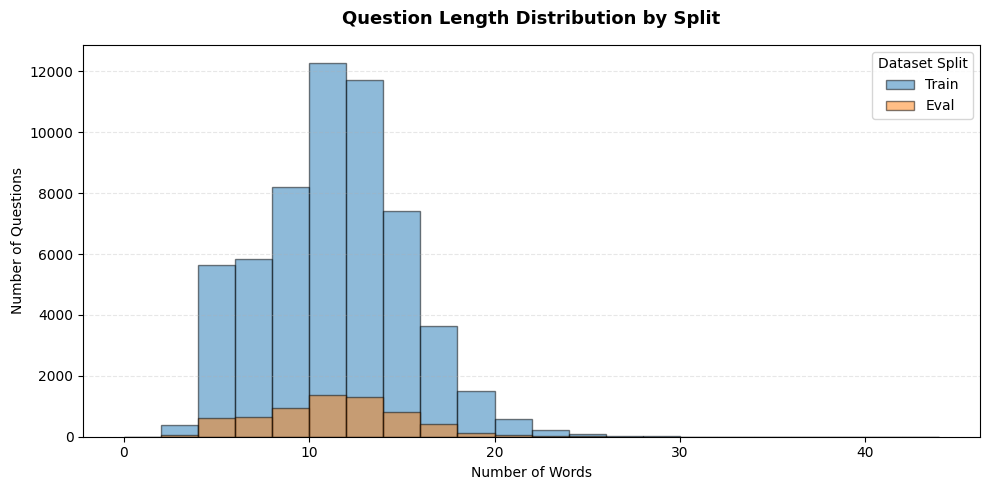

In [27]:
# ── Question Length Distribution ──

plt.figure(figsize=(10, 5), dpi=100)

for split in ["train", "eval"]:
    split_data = words_df.loc[
      # Condition, Label
      words_df["Split"] == split,
      "Count"
    ]

    plt.hist(
        split_data,
        bins=range(0, 46, 2),
        alpha=0.5,
        label=split.capitalize(),
        edgecolor="black"
    )

plt.title("Question Length Distribution by Split", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Number of Words")
plt.ylabel("Number of Questions")
plt.legend(title="Dataset Split")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# **Section 4 – Text Statistics**

In [28]:
word_stats = []
for split in configs["pretrain"]:
  dataset = load_dataset(
    REPO,
    "pretrain",
    split = split,
    streaming = True
  )

  total_words = 0
  total_records = 0

  max_words = 0
  min_words = float("inf")

  for record in tqdm(dataset, desc = f"Pretrain - {split}: "):
    word_count = len(record["text"].split())

    total_words += word_count
    total_records +=1

    min_words = min(min_words, word_count)
    max_words = max(max_words, word_count)

  word_stats.append({
    "Split": split,
    "Records": total_records,
    "Total Words": total_words,
    "Mean Words": total_words / total_records,
    "Min Words": min_words,
    "Max Words": max_words
  })

word_stats_df = pd.DataFrame(word_stats)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Pretrain - train: : 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Pretrain - eval: : 0it [00:00, ?it/s]

... (8 outputs left out)

Pretrain - phase2_train: : 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Pretrain - phase2_eval: : 0it [00:00, ?it/s]

In [29]:
display(
  word_stats_df.style.format({
    "Records": "{:,.0f}",
    "Total Words": "{:,.0f}",
    "Mean Words": "{:.2f}",
    "Min Words": "{:.0f}",
    "Max Words": "{:.0f}"
  }).set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

,Split,Records,Total Words,Mean Words,Min Words,Max Words
0,train,"7,053,893","464,098,245",65.79,1,571
1,eval,"114,259","7,447,636",65.18,1,335
2,phase1_train,"175,476","44,318,760",252.56,6,3813
3,phase1_eval,"2,000","508,231",254.12,39,1511
4,phase2_train,"94,486","22,430,726",237.40,17,3813
5,phase2_eval,"2,001","467,968",233.87,40,2561


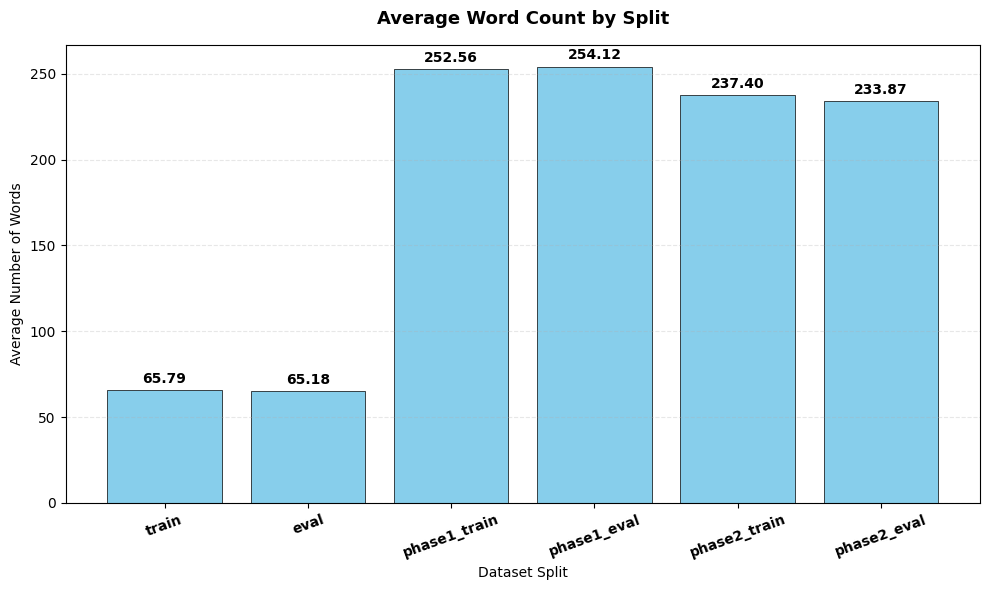

In [30]:
# ── Average Word Count by Split ──

plt.figure(figsize=(10, 6), dpi=100)

ax = plt.bar(
    word_stats_df["Split"],
    word_stats_df["Mean Words"],
    edgecolor="black",
    linewidth=0.5,
    color="skyblue"
)

# Add value labels
plt.bar_label(
    ax,
    fmt="%.2f",
    padding=3,
    fontsize=10,
    fontweight="bold"
)

plt.title("Average Word Count by Split", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Dataset Split")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=20, ha="center", fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Key Findings:**

- **Main Pretraining:** The average text length is approximately 66 words across both training and evaluation splits.
- **Phase 1:** Texts are substantially longer, averaging approximately 253 words.
- **Phase 2:** Texts average approximately 235 words, slightly shorter than Phase 1.
- **Split Consistency:** Training and evaluation splits show similar average text lengths within each dataset stage.
- **Maximum Length:** Phase 1 and Phase 2 contain substantially longer texts, reaching up to 3,813 words.

Overall, the three pretraining stages exhibit distinct text-length characteristics, with Phase 1 and Phase 2 containing considerably longer texts than the main pretraining dataset.

# **Section 5 – Question-Answer Analysis.**

## **5.1 – Answer Length Analysis.**

In [31]:
# ── Answer Length Analysis ──

answer_words = []

for split in configs["finetune"]:
    dataset = load_dataset(
        REPO,
        "finetune",
        split=split,
        streaming=True
    )

    for record in dataset:
        answer_words.append({
            "Split": split,
            "Count": len(record["answer"].split())
        })

answer_words_df = pd.DataFrame(answer_words)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

In [32]:
display(
  answer_words_df.sample(10).style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

,Split,Count
20425,train,26
9605,train,6
21025,train,16
37233,train,16
8854,train,21
32400,train,26
1734,train,16
48189,train,17
6646,train,27
40349,train,11


In [33]:
display(
  answer_words_df.groupby("Split")["Count"]
  .describe()
  .style.format("{:.2f}").set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

,count,mean,std,min,25%,50%,75%,max
Split,,,,,,,,
eval,6379.00,20.37,9.07,4.00,13.00,18.00,27.00,67.00
train,57488.00,20.06,9.05,3.00,13.00,18.00,27.00,62.00


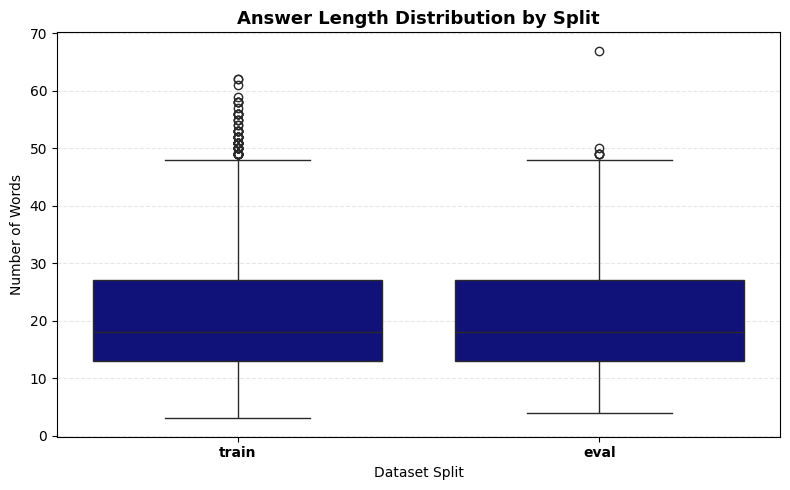

In [34]:
# ── Answer Length Distribution by Split ──

plt.figure(figsize=(8, 5), dpi=100)

sns.boxplot(
    data=answer_words_df,
    x="Split",
    y="Count",
    color = "darkblue"
)

plt.title("Answer Length Distribution by Split", fontsize=13, fontweight="bold")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Words")
plt.xticks(rotation=0, ha="center", fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Key Findings:**

- **Similar Average Length:** The average answer length is nearly identical across the training and evaluation splits (20.06 vs. 20.37 words).
- **Consistent Distribution:** Both splits share the same median (18 words) and interquartile range (13–27 words).
- **Similar Variability:** The standard deviation is almost identical, indicating comparable variation in answer lengths.
- **Maximum Length:** The longest answer contains 67 words in the evaluation split and 62 words in the training split.

Overall, the answer-length statistics are highly consistent across the training and evaluation splits.

## **5.2 – Question vs. Answer Length.**

In [35]:
# ── Question vs. Answer Length ──

qa_length_data = []

for split in configs["finetune"]:
    dataset = load_dataset(
        REPO,
        "finetune",
        split=split,
        streaming=True
    )

    for record in dataset:
        qa_length_data.append({
            "Split": split,
            "Question Length": len(record["question"].split()),
            "Answer Length": len(record["answer"].split())
        })

qa_length_df = pd.DataFrame(qa_length_data)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

In [36]:
display(
  qa_length_df
)

,Split,Question Length,Answer Length
0,train,4,15
1,train,4,15
2,train,13,32
3,train,5,12
4,train,5,16
...,...,...,...
63862,eval,11,34
63863,eval,13,7
63864,eval,9,14
63865,eval,9,17


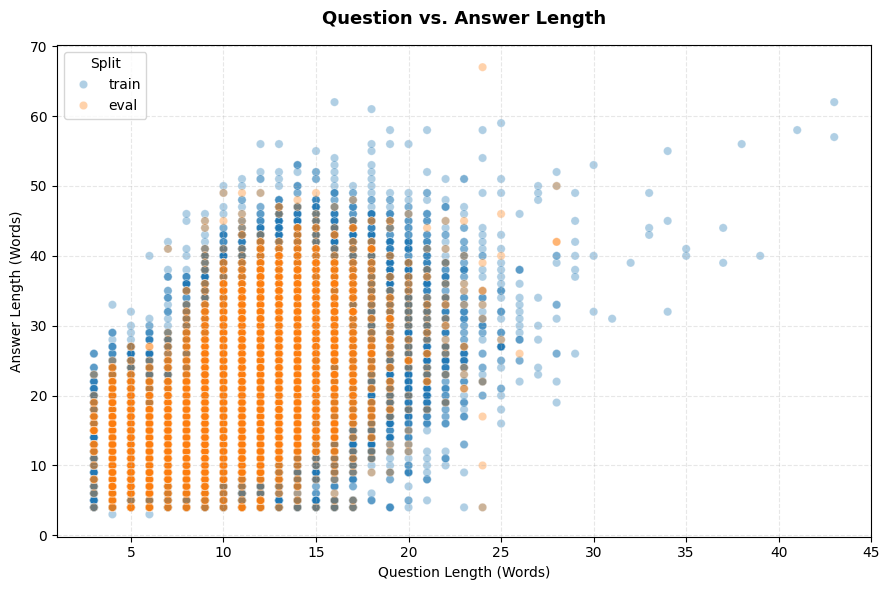

In [37]:
# ── Question vs. Answer Length ──

plt.figure(figsize=(9, 6), dpi=100)

sns.scatterplot(
    data=qa_length_df,
    x="Question Length",
    y="Answer Length",
    hue="Split",
    alpha=0.35
)

plt.title("Question vs. Answer Length", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Question Length (Words)")
plt.ylabel("Answer Length (Words)")
plt.grid(linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

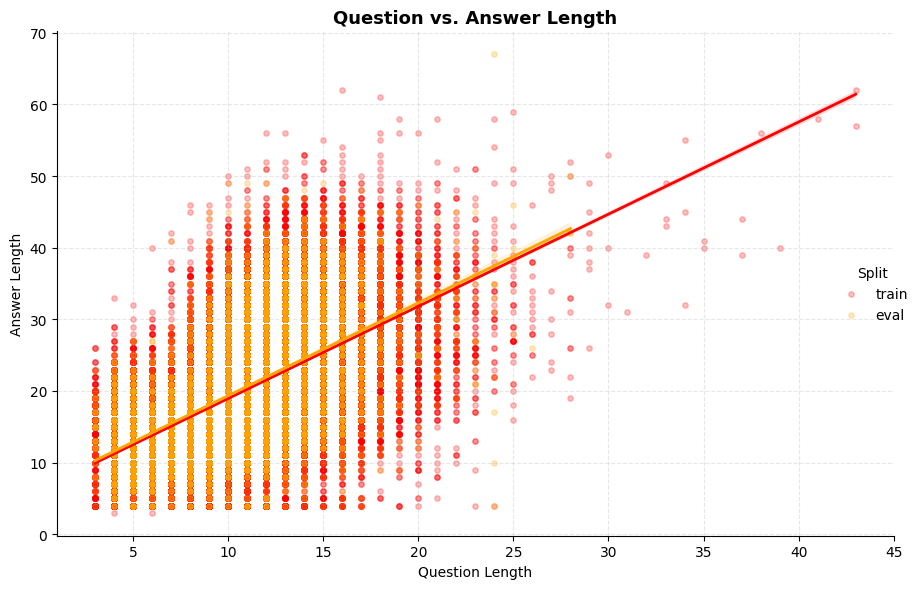

In [38]:
# ── Question vs. Answer Length ──

plt.figure(figsize=(12, 6), dpi=100)

sns.lmplot(
  data=qa_length_df,
  x="Question Length",
  y="Answer Length",
  hue="Split",
  height=6,
  aspect=1.4,
  palette={
      "train": "red",
      "eval": "orange"
  },
  scatter_kws={"alpha": 0.25, "s": 15},
  line_kws={"linewidth": 2}
)

plt.title("Question vs. Answer Length", fontsize = 13, fontweight="bold")
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Key Findings:**

- **Positive Relationship:** The regression lines show a positive relationship between question length and answer length, indicating that longer questions tend to be associated with longer answers.
- **Consistent Trends:** Both training and evaluation splits exhibit similar upward trends.
- **High Variability:** The scatter plot shows considerable variation in answer lengths for questions of similar lengths.
- **Data Concentration:** Most observations are concentrated around question lengths of 8–20 words, with answer lengths varying considerably.
- **Long Questions:** A small number of questions have considerably greater lengths than the majority of the dataset.

Overall, question length shows a positive relationship with answer length, although substantial variability remains across individual question-answer pairs.

# **Section 6 – Data Quality Over Finetune Data.**

In [39]:
# ── 06 – Data Quality Analysis ──

from collections import Counter
import pandas as pd

quality_stats = []
duplicate_stats = []
empty_stats = []
label_stats = []

for split in configs["finetune"]:

    dataset = load_dataset(
        REPO,
        "finetune",
        split=split,
        streaming=True
    )

    missing_counts = Counter()
    duplicate_counts = Counter()
    empty_counts = Counter()

    label_counts = {
        "type": Counter(),
        "difficulty": Counter(),
        "language": Counter()
    }

    seen_records = set()
    total_records = 0
    columns = None

    for record in dataset:
        total_records += 1

        # Get dataset columns
        if columns is None:
            columns = list(record.keys())

        # 1. Missing Values
        for column, value in record.items():
            if value is None:
                missing_counts[column] += 1

        # 2. Duplicate Records
        record_key = (
            record.get("question"),
            record.get("answer")
        )

        if record_key in seen_records:
            duplicate_counts["Duplicate"] += 1
        else:
            seen_records.add(record_key)

        # 3. Empty Text
        for column in ["question", "answer"]:
            value = record.get(column)

            if value is None or (
                isinstance(value, str) and not value.strip()
            ):
                empty_counts[column] += 1

        # 4. Label Distribution
        for column in label_counts:
            label_counts[column][record.get(column)] += 1

    # ── Store Missing Values ──
    for column in columns:
        count = missing_counts[column]

        quality_stats.append({
            "Split": split,
            "Column": column,
            "Missing Count": count,
            "Missing Percentage": count / total_records * 100
        })

    # ── Store Duplicates ──
    duplicate_stats.append({
        "Split": split,
        "Total Records": total_records,
        "Duplicate Records": duplicate_counts["Duplicate"]
    })

    # ── Store Empty Text ──
    for column in ["question", "answer"]:
        empty_stats.append({
            "Split": split,
            "Column": column,
            "Empty Count": empty_counts[column]
        })

    # ── Store Label Distribution ──
    for column, counts in label_counts.items():
        for label, count in counts.items():
            label_stats.append({
                "Split": split,
                "Column": column,
                "Label": label,
                "Count": count
            })


# ── Convert Results to DataFrames ──

missing_df = pd.DataFrame(quality_stats)
duplicates_df = pd.DataFrame(duplicate_stats)
empty_df = pd.DataFrame(empty_stats)
labels_df = pd.DataFrame(label_stats)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

##### **Display Results:**

In [40]:
print("Missing Values")
display(
  missing_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Missing Values


,Split,Column,Missing Count,Missing Percentage
0,train,difficulty,0,0.000000
1,train,type,0,0.000000
2,train,qa_id,0,0.000000
3,train,dataset_version,0,0.000000
4,train,question,0,0.000000
5,train,article_title,0,0.000000
6,train,answer,0,0.000000
7,train,source_article_id,0,0.000000
8,train,language,0,0.000000
9,eval,difficulty,0,0.000000


In [41]:
print("Duplicate Records")
display(
  duplicates_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Duplicate Records


,Split,Total Records,Duplicate Records
0,train,57488,186
1,eval,6379,1


In [42]:
print("Empty Text")
display(
  empty_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Empty Text


,Split,Column,Empty Count
0,train,question,0
1,train,answer,0
2,eval,question,0
3,eval,answer,0


In [43]:
print("Label Distribution")
display(
  labels_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Label Distribution


,Split,Column,Label,Count
0,train,type,factual,17752
1,train,type,temporal,18157
2,train,type,analytical,17761
3,train,type,synthesis,2615
4,train,type,unanswerable,1203
5,train,difficulty,easy,27500
6,train,difficulty,hard,17126
7,train,difficulty,medium,12862
8,train,language,ar,44947
9,train,language,en,12541


**Key Findings:**

- **No Missing Values:** All nine columns have zero missing values across both training and evaluation splits.
- **No Empty Text:** No empty questions or answers were detected in either split.
- **Duplicate QA Pairs:** The training split contains 186 duplicate question-answer pairs (approximately 0.32%), while the evaluation split contains only one (approximately 0.02%).
- **Label Distribution:** The observed values for `type`, `difficulty`, and `language` are consistent with the categories identified during the earlier analysis.
- **Unknown Label:** One evaluation record has an `unknown` question type, which should be investigated separately.

**Overall:** The dataset has no detected missing or empty values. Duplicate question-answer pairs are present in small numbers, particularly in the training split, and one unusual label was found in the evaluation split.

# **Section 7: Train–Eval Leakage Analysis In Finetune Subset.**

In [44]:
# – Train–Eval Leakage Analysis ─

train_sets = {
  "question": set(),
  "answer": set(),
  "qa_pair": set(),
  "source_article_id": set()
}

eval_sets = {
  "question": set(),
  "answer": set(),
  "qa_pair": set(),
  "source_article_id": set()
}


# ── Collect Train and Eval Data ──

for split in configs["finetune"]:

    dataset = load_dataset(
        REPO,
        "finetune",
        split=split,
        streaming=True
    )

    target_sets = train_sets if split == "train" else eval_sets

    for record in dataset:

        question = record.get("question")
        answer = record.get("answer")
        source_id = record.get("source_article_id")

        # Normalize text
        question = question.strip() if isinstance(question, str) else None
        answer = answer.strip() if isinstance(answer, str) else None
        source_id = source_id.strip() if isinstance(source_id, str) else None

        # Collect unique values
        if question:
            target_sets["question"].add(question)

        if answer:
            target_sets["answer"].add(answer)

        if question and answer:
            target_sets["qa_pair"].add((question, answer))

        if source_id:
            target_sets["source_article_id"].add(source_id)


# ── Calculate Train–Eval Overlap ──

leakage_results = []

metric_names = {
  "question": "Question Overlap",
  "answer": "Answer Overlap",
  "qa_pair": "Question–Answer Pair Overlap",
  "source_article_id": "Source Article Overlap"
}

for key, metric in metric_names.items():

    overlap = train_sets[key] & eval_sets[key]

    eval_unique = len(eval_sets[key])
    overlap_count = len(overlap)

    overlap_percentage = (
      (overlap_count / eval_unique) * 100
      if eval_unique > 0 else 0
    )

    leakage_results.append({
        "Metric": metric,
        "Overlap Count": overlap_count,
        "Eval Unique Count": eval_unique,
        "Overlap Percentage": overlap_percentage
    })


# ── Display Results ──

leakage_df = pd.DataFrame(leakage_results)

display(
  leakage_df.style.set_properties(**{'background-color':'#2a9d8f','color':'black','border':'2.5px solid black'})
)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

,Metric,Overlap Count,Eval Unique Count,Overlap Percentage
0,Question Overlap,192,6363,3.017445
1,Answer Overlap,65,6297,1.032238
2,Question–Answer Pair Overlap,35,6378,0.548761
3,Source Article Overlap,0,1972,0.000000


**Key Findings – Train–Eval Leakage Analysis**

- **Question Overlap:** 192 unique evaluation questions (3.02%) are also present in the training split.
- **Answer Overlap:** 65 unique evaluation answers (1.03%) are shared between the two splits.
- **Question–Answer Pair Overlap:** 35 identical question-answer pairs (0.55%) appear in both splits.
- **Source Article Isolation:** No overlapping source article IDs were detected between training and evaluation splits.

**Overall:** Although some exact question, answer, and question–answer pair overlaps exist, no shared source article IDs were found. This suggests that the splits are separated at the source-article level, while a small amount of exact textual overlap remains and may warrant further investigation.

# **Section 8 – Token Length Analysis.**

In [45]:
# ── Approximate Token Count per Sample ──

for config, splits in configs.items():

  for split in splits:
    dataset = load_dataset(
        REPO,
        config,
        split=split,
        streaming=True
    )

    approx_tokens = []

    for record in tqdm(
        dataset,
        desc=f"{config.capitalize()} | {split.capitalize()}"
      ):

      if config == "pretrain":
          char_count = len(record["text"])

      else:
          char_count = (
              len(record["question"]) +
              len(record["answer"])
          )

      estimated_tokens = char_count / CHARS_PER_TOKEN
      approx_tokens.append(estimated_tokens)

    # ── Display Statistics ──
    approx_tokens = pd.Series(approx_tokens)

    print(f"\n=== {config.upper()} | {split.upper()} ===")
    print(
        approx_tokens
        .describe()
        .round(1)
    )

    # ── Context Length Coverage ──
    for ctx in CONTEXT_LENGTHS:

      dropped_pct = (
        (approx_tokens > ctx).mean() * 100
      )

      kept_pct = 100 - dropped_pct

      print(
        f"Max_length={ctx:>4} | "
        f"Kept: {kept_pct:.1f}% | "
        f"Truncated: {dropped_pct:.1f}%"
      )

    print("=" * 56)

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Pretrain | Train: 0it [00:00, ?it/s]


=== PRETRAIN | TRAIN ===
count    7053893.0
mean         113.8
std           81.0
min           34.3
25%           55.1
50%           88.3
75%          144.6
max          428.6
dtype: float64
Max_length= 512 | Kept: 100.0% | Truncated: 0.0%
Max_length=1024 | Kept: 100.0% | Truncated: 0.0%
Max_length=2048 | Kept: 100.0% | Truncated: 0.0%


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

... (20 outputs left out)


=== FINETUNE | TRAIN ===
count    57488.0
mean        52.6
std         21.9
min          9.7
25%         35.4
50%         48.6
75%         69.4
max        197.4
dtype: float64
Max_length= 512 | Kept: 100.0% | Truncated: 0.0%
Max_length=1024 | Kept: 100.0% | Truncated: 0.0%
Max_length=2048 | Kept: 100.0% | Truncated: 0.0%


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Finetune | Eval: 0it [00:00, ?it/s]


=== FINETUNE | EVAL ===
count    6379.0
mean       53.1
std        21.9
min        10.9
25%        35.7
50%        49.1
75%        70.0
max       195.1
dtype: float64
Max_length= 512 | Kept: 100.0% | Truncated: 0.0%
Max_length=1024 | Kept: 100.0% | Truncated: 0.0%
Max_length=2048 | Kept: 100.0% | Truncated: 0.0%


### **Key Findings – Token Length Analysis**

- **Main Pretraining Splits:** The main pretraining train and eval splits have similar average lengths of approximately 113 tokens, with all samples fitting within a 512-token context window.
- **Phase 1:** Phase 1 samples are considerably longer, averaging approximately 444–447 tokens. A 512-token window retains only around 61% of samples, while 1024 tokens covers more than 99%.
- **Phase 2:** Phase 2 samples average approximately 404–408 tokens. A 512-token window retains around 73% of samples, while 1024 tokens covers approximately 99%.
- **Fine-tuning:** Train and eval samples have similar average lengths of approximately 53 tokens, and all samples fit within a 512-token window.
- **Long Samples:** Some Phase 1 and Phase 2 samples exceed 2048 tokens, indicating a long-tail distribution.

**Overall:**
- A __512-token__ context window is sufficient for the main pretraining and fine-tuning splits, but it truncates a considerable proportion of Phase 1 and Phase 2 samples.
- A __1024-token__ window provides a much **better coverage** across all **configurations, retaining approximately 99% or more of the samples**.

# <a id="Import"></a><div style="background: linear-gradient(to right, #1b5e20, #2e7d32, #388e3c, #43a047, #4caf50); font-family: 'Times New Roman', serif; font-size: 28px; font-weight: bold; text-align: center; border-radius: 15px; padding: 15px; border: 2px solid #ffffff; box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">Thanks & Upvote ❤️</div>